# SMSD Pro tools for AI models

This notebook uses SMSD 8.2.1 or later to offer its eight molecular tools to a language
model. It calls each tool directly with no model, runs a complete tool loop
driven by a scripted model, repeats the loop against an open model served on
your own machine, and closes with short cells for hosted model APIs. The tools
run on your machine and contact no network service. A hosted API receives the
question, every tool argument and every tool result, structures included.
Where structures must stay on your own hardware, as in many academic and
pharmaceutical projects, use a local open model; the notebook covers that
route first.

The scripted tool loop runs offline. Local and hosted model requests are off
by default: set `RUN_LOCAL_MODEL` or `RUN_HOSTED_APIS` to `True` in the setup
cell to enable only the section you intend to run.

## Setup

Run the next cell first in Colab or local Jupyter. It installs SMSD Pro into
the current kernel, using that kernel's Python; the model clients are
installed separately, as each model section explains. An already installed
SMSD 8.2.1 or later is kept. Installation needs internet access; the chemistry
examples use inline inputs. No wheel upload or copied setup cell is needed.

If an older SMSD is already imported, restart the kernel before running
setup. See [Installation](https://asad.github.io/SMSD/HOWTO-INSTALL/).


In [1]:
# Run this cell first in Colab or a local Jupyter kernel.
import importlib
import importlib.metadata
import importlib.util
import subprocess
import sys

if sys.version_info < (3, 12):
    raise RuntimeError("Select a Python 3.12 or later kernel for SMSD Pro wheels")

try:
    _smsd_version = importlib.metadata.version("smsd")
except importlib.metadata.PackageNotFoundError:
    _smsd_version = "0.0.0"
_smsd_parts = tuple(int(part) for part in _smsd_version.split(".")[:3]
                    if part.isdigit())
_requirements = []
if importlib.util.find_spec("smsd") is None or _smsd_parts < (8, 2, 1):
    if "smsd" in sys.modules:
        raise RuntimeError("Restart the kernel, then run this setup cell before importing SMSD")
    _requirements.append("smsd>=8.2.1,<9")
if _requirements:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", "--only-binary=:all:",
         *_requirements], check=True,
    )
    importlib.invalidate_caches()
_optional_packages = {}
_optional_requirements = [_package for _module, _package in _optional_packages.items()
                          if importlib.util.find_spec(_module) is None]
if _optional_requirements:
    try:
        subprocess.run(
            [sys.executable, "-m", "pip", "install", "--quiet", "--only-binary=:all:",
             *_optional_requirements], check=True,
        )
    except subprocess.CalledProcessError:
        print("Some optional packages have no compatible wheel or could not be downloaded. "
              "The affected cells will report what is missing; SMSD remains available.")
    importlib.invalidate_caches()
import smsd
print("Using SMSD", smsd.__version__)

RUN_LOCAL_MODEL = False
RUN_HOSTED_APIS = False


Using SMSD 8.2.1


In [2]:
# Responsive figures with a caption, an accessible image and an SVG fallback.
import base64
from html import escape


def show_svg(svg_text, description, max_width=800):
    image_uri = "data:image/svg+xml;base64," + base64.b64encode(
        svg_text.encode("utf-8")).decode("ascii")
    figure = (
        f'<figure style="margin:1em 0;max-width:{int(max_width)}px">'
        f'<img src="{image_uri}" alt="{escape(description, quote=True)}" '
        'style="display:block;width:100%;height:auto;box-sizing:border-box;'
        'background:#fff;border:1px solid #d5dce3;border-radius:8px;padding:16px">'
        f'<figcaption style="margin-top:0.6em;line-height:1.5">{escape(description)}</figcaption>'
        '</figure>'
    )
    try:
        from IPython.display import display
    except ImportError:
        print(description)
    else:
        display({"text/html": figure, "image/svg+xml": svg_text,
                 "text/plain": description}, raw=True,
                metadata={"image/svg+xml": {"alt": description}})


def show_table(frame):
    try:
        from IPython.display import display
    except ImportError:
        print(frame.to_string())
    else:
        display(frame)


In [3]:
# Uses the SMSD package prepared by the setup cell.
import json
import os
import re

import smsd
from smsd.tool_definitions import TOOL_REGISTRY, call_tool, get_tool_definitions

_release = tuple(int(part) for part in re.findall(r"\d+", smsd.__version__)[:3])
if _release < (8, 2, 1):
    raise RuntimeError("Use SMSD 8.2.1 or later in this notebook's kernel")
print("Using SMSD", smsd.__version__)

molecules = {
    "aspirin": "CC(=O)Oc1ccccc1C(=O)O",
    "salicylic acid": "OC(=O)c1ccccc1O",
    "ibuprofen": "CC(C)Cc1ccc(cc1)C(C)C(=O)O",
}
aspirin, salicylic_acid, ibuprofen = molecules.values()

Using SMSD 8.2.1


## The eight tools

`TOOL_REGISTRY` holds each tool's function and JSON schema.
`get_tool_definitions(provider)` exports the eight definitions in the shape a
model API expects: `mcp` for MCP tool lists, `input-schema` for the Claude
Messages API, `function` for the OpenAI Responses API and, with one change,
the Gemini API, and `chat-function` for Chat Completions-compatible servers
such as DeepSeek, Ollama, vLLM, llama.cpp and LM Studio. Exporting a
definition contacts no service.

In [4]:
for name, tool in TOOL_REGISTRY.items():
    print(f"{name}: needs {', '.join(tool.input_schema['required'])}")
    print(f"    {tool.description}")

for provider in ("mcp", "input-schema", "function", "chat-function"):
    print(f"{provider}: {sorted(get_tool_definitions(provider)[0])}")

find_mcs: needs query_smiles, target_smiles
    Find one common graph and retain native proof and stopping flags.
find_substructure: needs query, target_smiles
    Find one SMARTS or molecule embedding, retaining native stopping status.
molecular_fingerprint: needs smiles
    Compute native set-bit positions or sparse position/count pairs, not an MCS proof.
search_smarts: needs query_smarts, target_smiles
    Enumerate bounded SMARTS embeddings without turning incomplete results into absence.
molecular_similarity: needs query_smiles, target_smiles
    Compare native fingerprints; the coefficient is not an MCS or biological-accuracy proof.
screen_molecules: needs query_smiles, targets_smiles
    Screen a bounded in-memory list by Tanimoto, with stable ranked ties and explicit pagination.
standardise_molecule: needs smiles
    Canonicalise representation; chemical transformations require explicit options and RDKit.
depict_mcs: needs query_smiles, target_smiles
    Return a native mapping

## Call each tool directly

`call_tool(name, arguments)` runs a tool with a dictionary of JSON values and
returns the same JSON-compatible result that a model receives. The cell below
calls all eight tools on aspirin, salicylic acid and ibuprofen. A search
result reports `status`, `optimal` and `complete`; an MCS is proved maximum
only when `optimal` is true. Fingerprint, similarity, screening and
standardisation results report `status` and `complete` only, because they
involve no search.

In [5]:
arguments = {
    "find_mcs": {"query_smiles": aspirin, "target_smiles": salicylic_acid},
    "find_substructure": {"query": "c1ccccc1C(=O)O", "target_smiles": aspirin,
                          "query_format": "smiles"},
    "search_smarts": {"query_smarts": "C(=O)[OX2H1]", "target_smiles": ibuprofen},
    "molecular_fingerprint": {"smiles": aspirin},
    "molecular_similarity": {"query_smiles": aspirin, "target_smiles": salicylic_acid},
    "screen_molecules": {"query_smiles": aspirin, "targets_smiles": [salicylic_acid, ibuprofen],
                         "threshold": 0.0},
    "standardise_molecule": {"smiles": "CC(=O)Oc1ccccc1C(=O)[O-].[Na+]"},
    "depict_mcs": {"query_smiles": aspirin, "target_smiles": salicylic_acid},
}
if set(arguments) != set(TOOL_REGISTRY):
    raise RuntimeError("Every registered tool should be called once")
results = {name: call_tool(name, values) for name, values in arguments.items()}

mcs = results["find_mcs"]
print("find_mcs:", mcs["matches"][0]["atom_count"], "atoms,", mcs["status"],
      "optimal:", mcs["optimal"], "complete:", mcs["complete"])
hit = results["find_substructure"]
print("find_substructure: salicylic acid skeleton in aspirin:", hit["found"], hit["status"])
acids = results["search_smarts"]
print("search_smarts: carboxylic acids in ibuprofen:", len(acids["matches"]),
      "truncated:", acids["truncated"])
bits = results["molecular_fingerprint"]
print("molecular_fingerprint:", bits["kind"], len(bits["values"]), "bits set of", bits["fp_size"])
similarity = results["molecular_similarity"]
print(f"molecular_similarity: aspirin and salicylic acid {similarity['metric']} "
      f"{similarity['score']:.3f}")
names = list(molecules)[1:]
for found in results["screen_molecules"]["hits"]:
    print(f"screen_molecules: {names[found['target_index']]} {found['score']:.3f}")
print("standardise_molecule:", results["standardise_molecule"]["smiles"])
drawing = results["depict_mcs"]
print("depict_mcs:", drawing["mime_type"], len(drawing["svg"]), "characters,",
      drawing["matches"][0]["atom_count"], "atoms highlighted")

if not (mcs["optimal"] and mcs["matches"][0]["atom_count"] == 10):
    raise RuntimeError("The MCS of aspirin and salicylic acid should be proved at 10 atoms")
if [found["target_index"] for found in results["screen_molecules"]["hits"]] != [0, 1]:
    raise RuntimeError("Salicylic acid should rank above ibuprofen")

find_mcs: 10 atoms, COMPLETED optimal: True complete: True
find_substructure: salicylic acid skeleton in aspirin: True COMPLETED
search_smarts: carboxylic acids in ibuprofen: 1 truncated: False
molecular_fingerprint: ecfp 36 bits set of 2048
molecular_similarity: aspirin and salicylic acid tanimoto 0.185
screen_molecules: salicylic acid 0.185
screen_molecules: ibuprofen 0.115
standardise_molecule: C(c1c(cccc1)OC(C)=O)([O-])=O.[Na+]
depict_mcs: image/svg+xml 19154 characters, 10 atoms highlighted


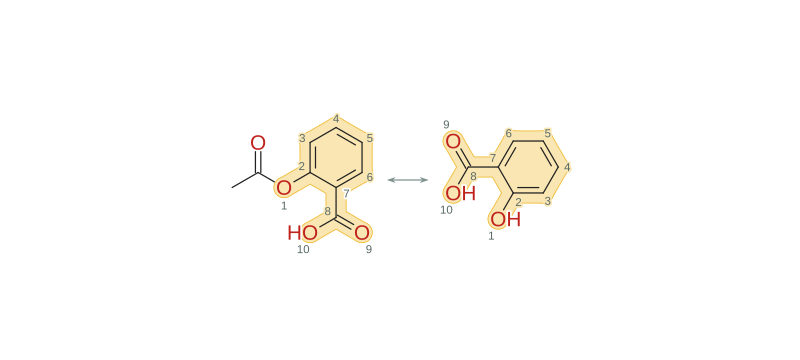

In [6]:
show_svg(results["depict_mcs"]["svg"],
         "Aspirin and salicylic acid with their common substructure highlighted.")


## Arguments are checked first

`call_tool` rejects unknown tools, unknown or missing arguments, wrong JSON
types and out-of-range values with a `ValueError` before any molecular work
begins. A tool loop returns the message to the model so that it can correct
the call.

In [7]:
for name, values in (("find_mcs", {"query_smiles": aspirin, "target_smiles": salicylic_acid,
                                   "objective": "largest"}),
                     ("find_mcs", {"query_smiles": aspirin}),
                     ("search_smarts", {"query_smarts": "C(=O)O", "target_smiles": aspirin,
                                        "max_matches": 1000})):
    try:
        call_tool(name, values)
    except ValueError as error:
        print(f"{name} refused: {error}")
    else:
        raise RuntimeError("The invalid call should have been refused")

find_mcs refused: objective is not an allowed value; allowed values: 'mcis', 'mces'
find_mcs refused: Missing required tool argument 'target_smiles' for find_mcs; required arguments: query_smiles, target_smiles
search_smarts refused: max_matches is outside its supported range; allowed range: 1 to 32


## A tool loop with a scripted model

In a tool loop the program sends the question and the tool definitions to the
model. The model replies either with tool calls or with its answer. The
program runs each call locally with `call_tool` and sends the whole result
back, including `status`, `optimal` and `complete`, then asks the model
again. An error goes back as text so that the model can correct its call;
the message names the allowed values of a fixed-choice argument, or the
tool's argument names after an unknown or missing argument.

`tool_loop` takes the `create` function of a Chat Completions client, so the
same loop serves the scripted model below, a local model server in the next
section and the DeepSeek API at the end. `QUESTION` asks for the MCS of
aspirin and salicylic acid and for the closer of two neighbours.

In [8]:
CHAT_TOOLS = get_tool_definitions("chat-function")
INSTRUCTIONS = ("Use the SMSD tools for every structural or similarity fact. "
                "For each search result, report status, optimal and complete.")
QUESTION = (f"Aspirin is {aspirin}, salicylic acid is {salicylic_acid} and ibuprofen is "
            f"{ibuprofen}. How many atoms does the maximum common substructure of aspirin "
            "and salicylic acid have, and is that result proven optimal? Which of salicylic "
            "acid and ibuprofen is more similar to aspirin by Tanimoto similarity of the "
            "default fingerprint?")


def run_tool(name, arguments):
    """Run one SMSD tool locally; errors go back to the model as text."""
    try:
        return json.dumps(call_tool(name, json.loads(arguments)))
    except (ValueError, ImportError) as error:
        return f"Error: {error}"


def tool_loop(create, model, question, max_turns=12):
    """Offer the tools, run each requested call locally and return (answer, calls).

    Each call is recorded as (name, arguments, outcome). The answer is None when
    the model is still calling tools after max_turns turns.
    """
    messages = [{"role": "system", "content": INSTRUCTIONS},
                {"role": "user", "content": question}]
    calls = []
    for _ in range(max_turns):
        message = create(model=model, messages=messages, tools=CHAT_TOOLS).choices[0].message
        messages.append(message)
        if not message.tool_calls:
            return message.content, calls
        for tool_call in message.tool_calls:
            output = run_tool(tool_call.function.name, tool_call.function.arguments)
            calls.append((tool_call.function.name, tool_call.function.arguments,
                          "error" if output.startswith("Error:") else "ok"))
            messages.append({"role": "tool", "tool_call_id": tool_call.id, "content": output})
    return None, calls


def show(calls, answer):
    """Print each tool call with its outcome, then the model's answer."""
    for name, arguments, outcome in calls:
        print(f"{outcome:>5}  {name} {arguments}")
    if answer is None:
        print("No answer within the turn limit.")
    else:
        print(answer.strip() or "The model returned an empty answer.")

The scripted model has the same call signature as
`client.chat.completions.create` and fixed replies: a call with an objective
that does not exist, the corrected MCS call with a screen of both neighbours,
and an answer written from the two results it receives.

In [9]:
from types import SimpleNamespace as Reply


class ScriptedModel:
    """Stands in for a Chat Completions endpoint with fixed replies."""

    def __init__(self):
        self.turn = 0

    @staticmethod
    def respond(content=None, calls=()):
        tool_calls = [Reply(id=f"call_{index}", type="function",
                            function=Reply(name=name, arguments=json.dumps(values)))
                      for index, (name, values) in enumerate(calls)]
        message = Reply(role="assistant", content=content, tool_calls=tool_calls or None)
        return Reply(choices=[Reply(message=message)])

    def create(self, model, messages, tools):
        if "find_mcs" not in {tool["function"]["name"] for tool in tools}:
            raise RuntimeError("The SMSD tools were not offered")
        self.turn += 1
        pair = {"query_smiles": aspirin, "target_smiles": salicylic_acid}
        if self.turn == 1:
            return self.respond(calls=[("find_mcs", {**pair, "objective": "largest"})])
        if self.turn == 2:
            return self.respond(calls=[
                ("find_mcs", pair),
                ("screen_molecules", {"query_smiles": aspirin,
                                      "targets_smiles": [salicylic_acid, ibuprofen],
                                      "threshold": 0.0})])
        found, screen = (json.loads(message["content"]) for message in messages[-2:])
        best, other = screen["hits"]
        closer = ("salicylic acid", "ibuprofen")[best["target_index"]]
        return self.respond(
            f"The maximum common substructure has {found['matches'][0]['atom_count']} atoms "
            f"(status {found['status']}, optimal {found['optimal']}, complete "
            f"{found['complete']}). By Tanimoto similarity, {closer} is closer to aspirin "
            f"({best['score']:.2f} against {other['score']:.2f}).")


answer, calls = tool_loop(ScriptedModel().create, "scripted", QUESTION)
show(calls, answer)
if [(name, outcome) for name, _, outcome in calls] != [
        ("find_mcs", "error"), ("find_mcs", "ok"), ("screen_molecules", "ok")]:
    raise RuntimeError("Unexpected tool calls")
if "10 atoms" not in answer or "salicylic acid is closer" not in answer:
    raise RuntimeError("The scripted answer does not match the direct tool results")

error  find_mcs {"query_smiles": "CC(=O)Oc1ccccc1C(=O)O", "target_smiles": "OC(=O)c1ccccc1O", "objective": "largest"}
   ok  find_mcs {"query_smiles": "CC(=O)Oc1ccccc1C(=O)O", "target_smiles": "OC(=O)c1ccccc1O"}
   ok  screen_molecules {"query_smiles": "CC(=O)Oc1ccccc1C(=O)O", "targets_smiles": ["OC(=O)c1ccccc1O", "CC(C)Cc1ccc(cc1)C(C)C(=O)O"], "threshold": 0.0}
The maximum common substructure has 10 atoms (status COMPLETED, optimal True, complete True). By Tanimoto similarity, salicylic acid is closer to aspirin (0.19 against 0.11).


## Local open models

Ollama serves an OpenAI-compatible endpoint at `http://localhost:11434/v1`,
so the same loop runs against a model on your own machine and no structure
leaves it. Pull a model with tool support first, for example
`ollama pull qwen3:8b` or `ollama pull gpt-oss:20b`. The cell runs only when
`RUN_LOCAL_MODEL` is `True` in the setup cell. It uses `qwen3:8b` unless the
environment variable `SMSD_LOCAL_MODEL` names another model, and skips with a
note when no server answers or the model is not available.

Ollama sets its default context from the available VRAM: below 24 GiB it is
4k tokens, which is small for eight tool definitions and their results.
Ollama recommends at least 64,000 tokens for agents and tool use, so start
the server with `OLLAMA_CONTEXT_LENGTH=64000 ollama serve`; a longer context
needs more memory.

vLLM, llama.cpp's `llama-server` and LM Studio also serve OpenAI-compatible
endpoints. Set `SMSD_LOCAL_BASE_URL` to the server's address, such as
`http://localhost:8000/v1` for vLLM, `http://localhost:9931/v1` for
`llama-server --port 9931` or `http://localhost:1234/v1` for LM Studio, and
`SMSD_LOCAL_MODEL` to a model ID that the server lists.
[Connecting AI assistants](https://asad.github.io/SMSD/AI_ASSISTANTS/) gives the
start command for each.

A model's answer can vary from run to run. Check it against the direct
results, which the cell prints after the answer.

In [10]:
from urllib.parse import urlsplit
from urllib.request import urlopen

try:
    from openai import APIError, OpenAI
except ImportError:
    OpenAI = None

LOCAL_BASE_URL = os.environ.get("SMSD_LOCAL_BASE_URL", "http://localhost:11434/v1")
LOCAL_MODEL = os.environ.get("SMSD_LOCAL_MODEL", "qwen3:8b")


def served_models(base_url):
    """The model IDs an OpenAI-compatible server lists, or None if none answers."""
    try:
        with urlopen(base_url.rstrip("/") + "/models", timeout=3) as response:
            return [item["id"] for item in json.load(response)["data"]]
    except (OSError, ValueError, KeyError, TypeError):
        return None


web_address = urlsplit(LOCAL_BASE_URL).scheme in ("http", "https")
available = served_models(LOCAL_BASE_URL) if RUN_LOCAL_MODEL and web_address else None
if not RUN_LOCAL_MODEL:
    print("Local model requests are disabled; set RUN_LOCAL_MODEL=True to enable them.")
elif not web_address:
    print("SMSD_LOCAL_BASE_URL must be an http or https address; skipping the local model.")
elif OpenAI is None:
    print("The openai package is not installed; skipping the local model.")
elif available is None:
    print(f"No model server answered at {LOCAL_BASE_URL}; skipping the local model.")
elif LOCAL_MODEL not in available:
    print(f"{LOCAL_MODEL} is not served at {LOCAL_BASE_URL}; available: {', '.join(available)}")
else:
    # A local server needs no key, but the client needs a value.
    local = OpenAI(base_url=LOCAL_BASE_URL, api_key="local", timeout=600)
    try:
        answer, calls = tool_loop(local.chat.completions.create, LOCAL_MODEL, QUESTION)
    except APIError as error:
        print(f"{LOCAL_MODEL} did not finish the loop: {error}")
    else:
        print("model:", LOCAL_MODEL)
        show(calls, answer)
        scores = [found["score"] for found in results["screen_molecules"]["hits"]]
        print(f"\nDirect results: {mcs['matches'][0]['atom_count']} atoms, optimal {mcs['optimal']}; "
              f"Tanimoto to aspirin: salicylic acid {scores[0]:.2f}, ibuprofen {scores[1]:.2f}")

Local model requests are disabled; set RUN_LOCAL_MODEL=True to enable them.


## Hosted models

Each cell below sends the question, every tool argument and every tool result,
structures included, to the vendor's API, and runs only when `RUN_HOSTED_APIS`
is `True` in the setup cell and its key variable is set. Set the key in your
shell before you start Jupyter, never in the notebook. A failed request prints
only the error type and HTTP status. Install the client first: `anthropic` for
the Claude Messages API, `openai` for the DeepSeek and OpenAI APIs, and
`google-genai` 2.33.0 or later for the Gemini API. The vendors are in
alphabetical order. The model IDs were current on 29 October 2026; check each
vendor's model list before you rely on one.

In [11]:
def report_failure(service, error):
    """Name a failed hosted request without repeating the service's error text."""
    status = getattr(error, "status_code", None) or getattr(error, "code", None)
    print(f"The {service} request failed: {type(error).__name__}"
          + (f", HTTP status {status}" if isinstance(status, int) else ""))

In [12]:
# Claude Messages API: input-schema definitions; reads ANTHROPIC_API_KEY.
try:
    import anthropic
except ImportError:
    anthropic = None


def ask_claude(question):
    client = anthropic.Anthropic()
    messages, calls = [{"role": "user", "content": question}], []
    for _ in range(12):
        response = client.messages.create(
            model="claude-opus-5-5", max_tokens=4096, system=INSTRUCTIONS,
            tools=get_tool_definitions("input-schema"), messages=messages)
        messages.append({"role": "assistant", "content": response.content})
        if response.stop_reason != "tool_use":
            return "".join(block.text for block in response.content if block.type == "text"), calls
        replies = []
        for block in response.content:
            if block.type == "tool_use":
                try:
                    text, is_error = json.dumps(call_tool(block.name, block.input)), False
                except (ValueError, ImportError) as error:
                    text, is_error = str(error), True
                calls.append((block.name, json.dumps(block.input), "error" if is_error else "ok"))
                replies.append({"type": "tool_result", "tool_use_id": block.id,
                                "content": text, "is_error": is_error})
        messages.append({"role": "user", "content": replies})
    return None, calls


if not RUN_HOSTED_APIS:
    print("Hosted requests are disabled; set RUN_HOSTED_APIS=True to enable them.")
elif not os.environ.get("ANTHROPIC_API_KEY"):
    print("ANTHROPIC_API_KEY is not set; skipping the Claude Messages API.")
elif anthropic is None:
    print("The anthropic package is not installed; skipping the Claude Messages API.")
else:
    try:
        answer, calls = ask_claude(QUESTION)
    except anthropic.APIError as error:
        report_failure("Claude Messages API", error)
    else:
        show(calls, answer)

Hosted requests are disabled; set RUN_HOSTED_APIS=True to enable them.


In [13]:
# DeepSeek API: the Chat Completions loop above; reads DEEPSEEK_API_KEY.
if not RUN_HOSTED_APIS:
    print("Hosted requests are disabled; set RUN_HOSTED_APIS=True to enable them.")
elif not os.environ.get("DEEPSEEK_API_KEY"):
    print("DEEPSEEK_API_KEY is not set; skipping the DeepSeek API.")
elif OpenAI is None:
    print("The openai package is not installed; skipping the DeepSeek API.")
else:
    # The DeepSeek key is sent only to the DeepSeek API.
    deepseek = OpenAI(base_url="https://api.deepseek.com", api_key=os.environ["DEEPSEEK_API_KEY"])
    try:
        answer, calls = tool_loop(deepseek.chat.completions.create, "deepseek-flash", QUESTION)
    except APIError as error:
        report_failure("DeepSeek API", error)
    else:
        show(calls, answer)

Hosted requests are disabled; set RUN_HOSTED_APIS=True to enable them.


In [14]:
# Gemini API: function definitions without additionalProperties; reads GEMINI_API_KEY.
try:
    from google import genai
    from google.genai import errors, types
except ImportError:
    genai = None


def ask_gemini(question):
    # call_tool still rejects unknown arguments.
    declarations = [
        {"name": tool["name"], "description": tool["description"],
         "parameters": {key: value for key, value in tool["parameters"].items()
                        if key != "additionalProperties"}}
        for tool in get_tool_definitions("function")]
    client = genai.Client()
    config = types.GenerateContentConfig(
        system_instruction=INSTRUCTIONS, store=False,
        tools=[types.Tool(function_declarations=declarations)])
    contents = [types.Content(role="user", parts=[types.Part(text=question)])]
    calls = []
    for _ in range(12):
        response = client.models.generate_content(
            model="gemini-3.8-flash", contents=contents, config=config)
        if not response.function_calls:
            return response.text, calls
        contents.append(response.candidates[0].content)
        parts = []
        for call in response.function_calls:
            try:
                reply = {"result": call_tool(call.name, call.args or {})}
            except (ValueError, ImportError) as error:
                reply = {"error": str(error)}
            calls.append((call.name, json.dumps(call.args or {}), "error" if "error" in reply else "ok"))
            parts.append(types.Part(function_response=types.FunctionResponse(
                id=call.id, name=call.name, response=reply)))
        contents.append(types.Content(role="user", parts=parts))
    return None, calls


if not RUN_HOSTED_APIS:
    print("Hosted requests are disabled; set RUN_HOSTED_APIS=True to enable them.")
elif not (os.environ.get("GEMINI_API_KEY") or os.environ.get("GOOGLE_API_KEY")):
    print("Neither GEMINI_API_KEY nor GOOGLE_API_KEY is set; skipping the Gemini API.")
elif genai is None:
    print("The google-genai package is not installed; skipping the Gemini API.")
else:
    try:
        answer, calls = ask_gemini(QUESTION)
    except errors.APIError as error:
        report_failure("Gemini API", error)
    else:
        show(calls, answer)

Hosted requests are disabled; set RUN_HOSTED_APIS=True to enable them.


In [15]:
# OpenAI Responses API: function definitions; reads OPENAI_API_KEY.
def ask_openai(question):
    client = OpenAI()
    input_list, calls = [{"role": "user", "content": question}], []
    for _ in range(12):
        response = client.responses.create(
            model="gpt-6-astra", instructions=INSTRUCTIONS,
            tools=get_tool_definitions("function"), input=input_list)
        input_list += response.output
        requested = [item for item in response.output if item.type == "function_call"]
        if not requested:
            return response.output_text, calls
        for item in requested:
            output = run_tool(item.name, item.arguments)
            calls.append((item.name, item.arguments, "error" if output.startswith("Error:") else "ok"))
            input_list.append({"type": "function_call_output", "call_id": item.call_id,
                               "output": output})
    return None, calls


if not RUN_HOSTED_APIS:
    print("Hosted requests are disabled; set RUN_HOSTED_APIS=True to enable them.")
elif not os.environ.get("OPENAI_API_KEY"):
    print("OPENAI_API_KEY is not set; skipping the OpenAI Responses API.")
elif OpenAI is None:
    print("The openai package is not installed; skipping the OpenAI Responses API.")
else:
    try:
        answer, calls = ask_openai(QUESTION)
    except APIError as error:
        report_failure("OpenAI Responses API", error)
    else:
        show(calls, answer)

Hosted requests are disabled; set RUN_HOSTED_APIS=True to enable them.


## Further reading

[Chemistry tools for AI assistants](https://asad.github.io/SMSD/guide/AI_TOOLS/) describes
each tool, its options and its limits.
[Connecting AI assistants](https://asad.github.io/SMSD/AI_ASSISTANTS/) connects the local MCP
server, `smsd-mcp`, to desktop and terminal assistants and gives the tool loop
for each model API.